<a href="https://colab.research.google.com/github/Sands225/Coral-Disease-Classification/blob/main/%5BSistem_Cerdas%5D_Coral_Disease_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Coral Disease Detection

**Mata Kuliah**: \
Sistem Cerdas A

\
**Dosen Pengampu**: \
Pak Agus Surya Darma

\
**Anggota Kelompok**:
| NIM | Nama |
| --- | --- |
| - | Naren |
| - | Satya |
| 2405551082 | I Made Sandika Wijaya

In [40]:
!pip install roboflow ultralytics albumentations opencv-python-headless pyyaml tqdm

In [41]:
from roboflow import Roboflow

from pathlib import Path
import os
import yaml
import json
import random
import shutil
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import matplotlib.patches as patches

In [42]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE_DIR = Path(
  "/content/drive/MyDrive/College/Sistem Cerdas/Coral Disease Detection/output"
)

WEIGHTS_DIR = DRIVE_DIR / "weights"
RESULTS_DIR = DRIVE_DIR / "results"
METRICS_DIR = DRIVE_DIR / "metrics"
CONFIG_DIR = DRIVE_DIR / "config"

for folder in [
  DRIVE_DIR, WEIGHTS_DIR,
  RESULTS_DIR, METRICS_DIR, CONFIG_DIR
]:
  folder.mkdir(parents=True, exist_ok=True)

print("Folder output:", DRIVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Folder output: /content/drive/MyDrive/College/Sistem Cerdas/Coral Disease Detection/output


## Dataset Collection
Tahapan ini merupakan tahapan pengumpulan data yang akan digunakan pada eksperimen ini. \
Dataset yang digunakan bersumber dari Roboflow, yaitu
[Marjan Detection v7](
https://universe.roboflow.com/maha-bil6y/marjan-detection/dataset/7).

Tahapan yang dilakukan pada proses ini adalah sebagai berikut.
1. Menghubungkan ke Roboflow untuk mengunduh gambar
2. Mengunduh dataset dari Roboflow dan disimpan pada storage local colab

In [43]:
# Setup untuk mengunduh dataset dari Roboflow
from google.colab import userdata
ROBOFLOW_KEY = userdata.get('ROBOFLOW_KEY')

rf = Roboflow(api_key=ROBOFLOW_KEY)
project = rf.workspace("maha-bil6y").project("marjan-detection")
version = project.version(7)
dataset = version.download("yolov11")

loading Roboflow workspace...
loading Roboflow project...


In [44]:
# Menyimpan dataset pada local Google Colab
dataset_path = "/content/marjan-detection-7"

for root, dirs, files in os.walk(dataset_path):
  level = root.replace(dataset_path, "").count(os.sep)
  indent = " " * 4 * level
  print(f"{indent}{os.path.basename(root)}/")

  for file in files[:5]:
    print(f"{indent}    {file}")

marjan-detection-7/
    README.roboflow.txt
    README.dataset.txt
    data.yaml
    train/
        labels.cache
        images/
            h30_jpg.rf.6822607e5209b516e3c6e5a1775ae932.jpg
            110_png_jpg.rf.074f7b05be21489aa6c947b913c2ac77.jpg
            260_png_jpg.rf.a41d1de835d0187ef760006c947cddf9.jpg
            Bleach_122_jpg.rf.31ecf6ef14f7a9d12c9723e0f729744c.jpg
            Bleach_137_jpg.rf.dd3097ca0fa2d4466c71c5719d578aec.jpg
        labels/
            B70_png_jpg.rf.e3a1f3f30d151cd37ea9de9a2df0fd33.txt
            ypi1mgj9e3-JPG-800x0_q85_jpg.rf.bb401764caec8ad3201a03e6a8e9f7b4.txt
            9pmckeu7ri-JPG-800x0_q85_jpg.rf.29d066f7d60193cdc34c848daddce45e.txt
            20_png_jpg.rf.00f116fd34b39831aea5a71ce9a3e43e.txt
            B103_png_jpg.rf.f5c48b6fb18ab537f25732313d399b6d.txt
    valid/
        labels.cache
        images/
            282_jpg.rf.5a498f5e489b9d6074c99cd088c20389.jpg
            4819583169_106ff643c9_o_jpg.rf.5b283979545fa8b943519db13dbf

Jumlah gambar: 3102


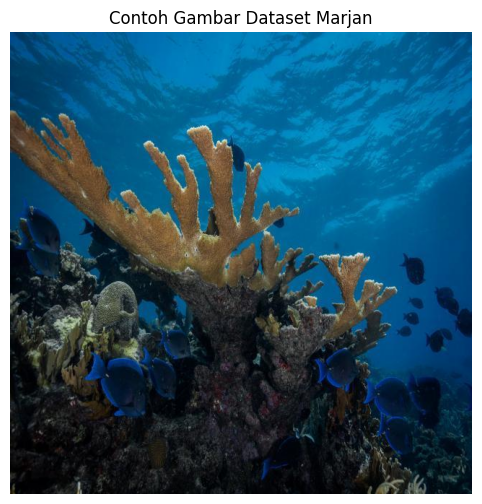

In [45]:
# Cari semua file gambar di dalam dataset
image_extensions = ["*.jpg", "*.jpeg", "*.png", "*.webp"]
image_files = []

for ext in image_extensions:
  image_files.extend(
    glob(os.path.join(dataset_path, "**", ext), recursive=True)
  )

print("Jumlah gambar:", len(image_files))

img = Image.open(image_files[0])

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.axis("off")
plt.title("Contoh Gambar Dataset Marjan")
plt.show()

## Dataset Preparation
Tahapan ini dilakukan dengan beberapa langkah, yaitu sebagai berikut.
1. Inspeksi dataset gambar dan anotasi
2. Melakukan splitting pada dataset (train, test, validation)
3. Verifikasi splitting
4. Augmentasi data training
    - Menerapkan flip horizontal/vertikal
    - Rotasi (-15° hingga +15°)
    - Shear (+10°)
    - Variasi saturasi (-25% hingga +25%)

### Data Inspection

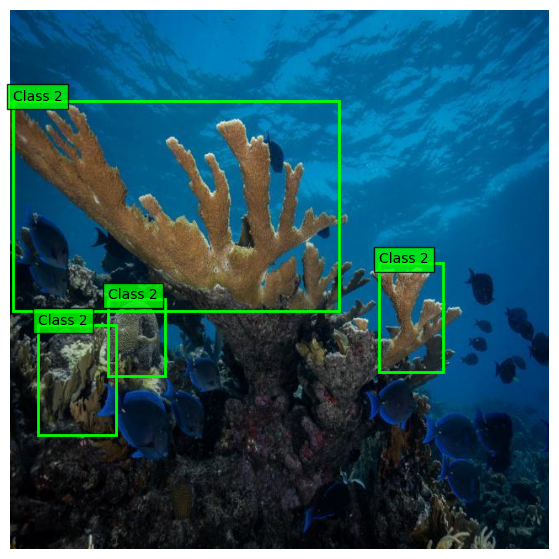

In [46]:
# Ambil gambar pertama
image_path = Path(image_files[0])
img = Image.open(image_path).convert("RGB")
img_width, img_height = img.size

# Cari file label dengan nama yang sama
label_path = None

for candidate in Path(dataset_path).rglob("*.txt"):
    if candidate.stem == image_path.stem:
        label_path = candidate
        break

fig, ax = plt.subplots(figsize=(10, 7))
ax.imshow(img)

if label_path is not None:
    with open(label_path, "r") as f:
        for line in f:
            values = line.split()

            if len(values) != 5:
                continue

            class_id, xc, yc, w, h = map(float, values)

            # Koordinat ternormalisasi menjadi piksel
            xc *= img_width
            yc *= img_height
            w *= img_width
            h *= img_height

            x = xc - w / 2
            y = yc - h / 2

            rect = patches.Rectangle(
                (x, y), w, h,
                linewidth=2,
                edgecolor="lime",
                facecolor="none"
            )

            ax.add_patch(rect)
            ax.text(x, y, f"Class {int(class_id)}",
                    color="black",
                    bbox=dict(facecolor="lime", alpha=0.8))

else:
    print("File label tidak ditemukan untuk gambar ini.")

ax.axis("off")
plt.show()


In [47]:
from pathlib import Path

yaml_files = list(Path(dataset_path).rglob("data.yaml"))

for yaml_file in yaml_files:
  print(f"File: {yaml_file}")
  print(yaml_file.read_text())

File: /content/marjan-detection-7/data.yaml
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['Bleached Coral', 'Dead Coral', 'Healthy Coral']

roboflow:
  workspace: maha-bil6y
  project: marjan-detection
  version: 7
  license: CC BY 4.0
  url: https://universe.roboflow.com/maha-bil6y/marjan-detection/dataset/7


### Data Augmentation

In [48]:
from pathlib import Path
import yaml
import random
import shutil
import cv2
import numpy as np
from tqdm.auto import tqdm
import albumentations as A


In [49]:
# Dataset asli dari Roboflow
SOURCE_DIR = Path("/content/marjan-detection-7")

# Dataset hasil augmentasi
OUTPUT_DIR = Path("/content/marjan-detection-augmented")

# Jumlah total gambar yang diinginkan
TARGET_TOTAL = 10285

# Seed untuk reproduksibilitas
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Dataset asli:", SOURCE_DIR)
print("Output:", OUTPUT_DIR)

Dataset asli: /content/marjan-detection-7
Output: /content/marjan-detection-augmented


In [50]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def get_images(folder):
  return sorted([
    p for p in folder.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
  ])

train_images = get_images(SOURCE_DIR / "train" / "images")
valid_images = get_images(SOURCE_DIR / "valid" / "images")
test_images = get_images(SOURCE_DIR / "test" / "images")

print(f"Train      : {len(train_images)}")
print(f"Validation : {len(valid_images)}")
print(f"Test       : {len(test_images)}")
print(f"Total      : {len(train_images) + len(valid_images) + len(test_images)}")

Train      : 2472
Validation : 272
Test       : 358
Total      : 3102


In [51]:
augmenter = A.Compose(
  [
    A.HorizontalFlip(p=0.5),

    A.Affine(
        rotate=(-15, 15),
        shear=(-10, 10),
        fit_output=False,
        border_mode=cv2.BORDER_CONSTANT,
        fill=(114, 114, 114),
        p=0.8
    ),

    A.ColorJitter(
        brightness=0,
        contrast=0,
        saturation=0.25,
        hue=0,
        p=0.8
    ),
  ],
  bbox_params=A.BboxParams(
      format="yolo",
      label_fields=["class_labels"],
      min_visibility=0.25
  )
)

In [52]:
# Baca konfigurasi Roboflow
with open(SOURCE_DIR / "data.yaml", "r") as f:
  data_config = yaml.safe_load(f)

def matching_label(image_path, image_dir, label_dir):
  relative = image_path.relative_to(image_dir).with_suffix(".txt")
  return label_dir / relative

# Hitung target total untuk training
fixed_eval_count = len(valid_images) + len(test_images)
target_train_count = TARGET_TOTAL - fixed_eval_count

if target_train_count < len(train_images):
  raise ValueError(
    "Target total lebih kecil daripada jumlah gambar asli "
    "yang harus dipertahankan."
  )

print("Target total dataset:", TARGET_TOTAL)
print("Target train:", target_train_count)
print("Validation tetap:", len(valid_images))
print("Test tetap:", len(test_images))

Target total dataset: 10285
Target train: 9655
Validation tetap: 272
Test tetap: 358


In [53]:
# Hati-hati: folder output lama akan dihapus agar tidak ada file
# sisa dari eksperimen sebelumnya.
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

for split in ["train", "valid", "test"]:
    (OUTPUT_DIR / split / "images").mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIR / split / "labels").mkdir(parents=True, exist_ok=True)

source_train_images = SOURCE_DIR / "train" / "images"
source_train_labels = SOURCE_DIR / "train" / "labels"

# Salin data training asli dan labelnya
for img_path in tqdm(train_images, desc="Menyalin train asli"):
    rel = img_path.relative_to(source_train_images)
    dst_img = OUTPUT_DIR / "train" / "images" / rel
    dst_label = OUTPUT_DIR / "train" / "labels" / rel.with_suffix(".txt")

    dst_img.parent.mkdir(parents=True, exist_ok=True)
    dst_label.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(img_path, dst_img)

    src_label = matching_label(
        img_path, source_train_images, source_train_labels
    )

    if src_label.exists():
        shutil.copy2(src_label, dst_label)
    else:
        # Jika gambar tanpa objek memang diizinkan, label kosong.
        dst_label.write_text("")

# Buat variasi gambar sampai mencapai target train
needed = target_train_count - len(train_images)
created = 0
attempts = 0
max_attempts = max(needed * 5, 100)

while created < needed and attempts < max_attempts:
    attempts += 1
    src_img = random.choice(train_images)

    src_label = matching_label(
        src_img, source_train_images, source_train_labels
    )

    image = cv2.imread(str(src_img))
    if image is None:
        continue

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    boxes = []
    classes = []

    if src_label.exists():
        for line in src_label.read_text().splitlines():
            values = line.split()
            if len(values) != 5:
                continue

            cls, xc, yc, w, h = map(float, values)
            boxes.append([xc, yc, w, h])
            classes.append(int(cls))

    try:
        transformed = augmenter(
            image=image,
            bboxes=boxes,
            class_labels=classes
        )
    except Exception:
        continue

    # Lewati jika gambar semula memiliki objek, tetapi semua box hilang
    if boxes and not transformed["bboxes"]:
        continue

    new_image = transformed["image"]
    new_boxes = transformed["bboxes"]
    new_classes = transformed["class_labels"]

    # Nama unik untuk gambar hasil augmentasi
    new_name = f"{src_img.stem}_aug_{created:06d}"
    out_img = OUTPUT_DIR / "train" / "images" / f"{new_name}.jpg"
    out_label = OUTPUT_DIR / "train" / "labels" / f"{new_name}.txt"

    new_image_bgr = cv2.cvtColor(new_image, cv2.COLOR_RGB2BGR)

    if not cv2.imwrite(str(out_img), new_image_bgr):
        continue

    with open(out_label, "w") as f:
        for cls, box in zip(new_classes, new_boxes):
            xc, yc, w, h = box
            f.write(
                f"{int(cls)} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n"
            )

    created += 1

if created < needed:
    raise RuntimeError(
        f"Hanya berhasil membuat {created} dari {needed} gambar yang diperlukan. "
        "Periksa anotasi dan parameter transformasi."
    )

print(f"Berhasil membuat {created} gambar augmented.")

Menyalin train asli:   0%|          | 0/2472 [00:00<?, ?it/s]

Berhasil membuat 7183 gambar augmented.


In [54]:
for split in ["valid", "test"]:
    source_images_dir = SOURCE_DIR / split / "images"
    source_labels_dir = SOURCE_DIR / split / "labels"

    for img_path in tqdm(
        get_images(source_images_dir),
        desc=f"Menyalin {split}"
    ):
        rel = img_path.relative_to(source_images_dir)

        dst_img = OUTPUT_DIR / split / "images" / rel
        dst_label = OUTPUT_DIR / split / "labels" / rel.with_suffix(".txt")

        dst_img.parent.mkdir(parents=True, exist_ok=True)
        dst_label.parent.mkdir(parents=True, exist_ok=True)

        shutil.copy2(img_path, dst_img)

        src_label = matching_label(
            img_path, source_images_dir, source_labels_dir
        )

        if src_label.exists():
            shutil.copy2(src_label, dst_label)
        else:
            dst_label.write_text("")

Menyalin valid:   0%|          | 0/272 [00:00<?, ?it/s]

Menyalin test:   0%|          | 0/358 [00:00<?, ?it/s]

In [55]:
output_config = {
    "path": str(OUTPUT_DIR),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": data_config["nc"],
    "names": data_config["names"]
}

output_yaml = OUTPUT_DIR / "data.yaml"

with open(output_yaml, "w") as f:
    yaml.safe_dump(output_config, f, sort_keys=False, allow_unicode=True)

print(output_yaml.read_text())

path: /content/marjan-detection-augmented
train: train/images
val: valid/images
test: test/images
nc: 3
names:
- Bleached Coral
- Dead Coral
- Healthy Coral



In [56]:
final_counts = {
    split: len(get_images(OUTPUT_DIR / split / "images"))
    for split in ["train", "valid", "test"]
}

print("Train      :", final_counts["train"])
print("Validation :", final_counts["valid"])
print("Test       :", final_counts["test"])
print("Total      :", sum(final_counts.values()))

assert final_counts["train"] == target_train_count
assert final_counts["valid"] == len(valid_images)
assert final_counts["test"] == len(test_images)
assert sum(final_counts.values()) == TARGET_TOTAL

print("Verifikasi jumlah gambar berhasil.")

Train      : 9655
Validation : 272
Test       : 358
Total      : 10285
Verifikasi jumlah gambar berhasil.


## Model Training
Tahap ini merupakan tahap dimana model dilatih. Langkah yang dilakukan pada proses ini adalah sebagai berikut.

In [ ]:
with open(DATA_YAML, "r") as f:
  data_config = yaml.safe_load(f)

print(yaml.safe_dump(data_config, sort_keys=False))

for split, key in [
  ("train", "train"),
  ("valid", "val"),
  ("test", "test")
]:
  relative_path = data_config.get(key)

  if relative_path is None:
    if split == "test":
      print("Peringatan: key 'test' belum ada di data.yaml.")
      continue
    raise ValueError(f"Key '{key}' tidak ditemukan dalam data.yaml.")

  base_path = Path(data_config.get("path", DATASET_DIR))
  if not base_path.is_absolute():
    base_path = DATASET_DIR / base_path

  image_dir = base_path / relative_path

  if not image_dir.exists():
    raise FileNotFoundError(f"Folder tidak ditemukan: {image_dir}")

  print(f"{split}: {image_dir} — OK")

In [57]:
MODEL_NAME = "yolo11n"
EPOCHS = 300
IMAGE_SIZE = 640
BATCH_SIZE = 16
LEARNING_RATE = 0.001

DEVICE = 0 if torch.cuda.is_available() else "cpu"

model = YOLO("yolo11n.pt")

train_results = model.train(
    data=str(DATA_YAML),

    # Hyperparameter training
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    optimizer="SGD",
    lr0=LEARNING_RATE,

    # Menghindari augmentasi tambahan karena dataset
    # sudah memiliki hasil augmentasi offline
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,
    degrees=0.0,
    translate=0.0,
    scale=0.0,
    shear=0.0,
    perspective=0.0,
    fliplr=0.0,
    flipud=0.0,
    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,

    # Reproducibility dan resource
    seed=42,
    deterministic=True,
    workers=2,
    device=DEVICE,
    amp=True,

    # Output langsung ke Google Drive
    project=str(RUNS_DIR),
    name="yolo11n_marjan",
    exist_ok=True,
    save=True,
    plots=True,
    verbose=True,

    # Berhenti lebih awal jika tidak ada perbaikan
    patience=50
)

print("Training selesai.")

Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/marjan-detection-7/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_baseline-3, nbs=64, nms=None, opset=None, o

KeyboardInterrupt: 

In [ ]:
RUN_DIR = RUNS_DIR / "yolo11n_marjan"
SOURCE_WEIGHTS = RUN_DIR / "weights"

best_source = SOURCE_WEIGHTS / "best.pt"
last_source = SOURCE_WEIGHTS / "last.pt"

if not best_source.exists():
    raise FileNotFoundError(f"Bobot best.pt tidak ditemukan: {best_source}")

shutil.copy2(best_source, WEIGHTS_DIR / "yolo11n_marjan_best.pt")

if last_source.exists():
    shutil.copy2(last_source, WEIGHTS_DIR / "yolo11n_marjan_last.pt")

print("Bobot terbaik:", WEIGHTS_DIR / "yolo11n_marjan_best.pt")
print("Bobot terakhir:", WEIGHTS_DIR / "yolo11n_marjan_last.pt")

## Model Evaluation

In [ ]:
best_model = YOLO(str(WEIGHTS_DIR / "yolo11n_marjan_best.pt"))

test_metrics = best_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    plots=True,
    project=str(RUNS_DIR),
    name="yolo11n_test",
    exist_ok=True,
    verbose=True
)

print("Evaluasi test selesai.")

## Export Results

In [ ]:
box = test_metrics.box

precision = float(box.mp)
recall = float(box.mr)

f1_score = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0
    else 0.0
)

summary = {
    "Model": "YOLO11n",
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1_score,
    "mAP@50": float(box.map50),
    "mAP@50-95": float(box.map),
    "Image Size": IMAGE_SIZE,
    "Batch Size": BATCH_SIZE,
    "Configured Epochs": EPOCHS,
    "Learning Rate": LEARNING_RATE,
    "Optimizer": "SGD"
}

summary_df = pd.DataFrame([summary])

summary_df.to_csv(
    METRICS_DIR / "yolo11n_test_summary.csv",
    index=False
)

with open(METRICS_DIR / "yolo11n_test_summary.json", "w") as f:
    json.dump(summary, f, indent=4)

display(summary_df)

In [ ]:
class_names = data_config["names"]

if isinstance(class_names, dict):
    class_names = [
        class_names[k]
        for k in sorted(class_names, key=lambda x: int(x))
    ]

per_class = []

for i, class_id in enumerate(box.ap_class_index):
    class_id = int(class_id)

    per_class.append({
        "Class ID": class_id,
        "Class Name": (
            class_names[class_id]
            if class_id < len(class_names)
            else f"Class {class_id}"
        ),
        "mAP@50": float(box.ap[i, 0]),
        "mAP@50-95": float(box.ap[i].mean())
    })

per_class_df = pd.DataFrame(per_class)

per_class_df.to_csv(
    METRICS_DIR / "yolo11n_per_class_metrics.csv",
    index=False
)

display(per_class_df)

In [ ]:
import matplotlib.pyplot as plt

metric_columns = [
    "Precision",
    "Recall",
    "F1-score",
    "mAP@50",
    "mAP@50-95"
]

plt.figure(figsize=(10, 5))
plt.bar(metric_columns, [summary[m] for m in metric_columns])
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("YOLO11n — Test Evaluation")
plt.xticks(rotation=15)
plt.tight_layout()

plot_path = METRICS_DIR / "yolo11n_test_metrics.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Grafik tersimpan:", plot_path)